# Part 5: Agent-Based Models

## Individual-Level Spatial Epidemic Simulation

---

## Why Aggregate Models Fail

All previous models (SIR, SEIR, Network, Degree-based) are **aggregate** models:
- Track **populations** or **classes**
- Use differential equations or mean-field approximations
- Cannot capture:
  - **Individual behaviors** (quarantine decisions, mask-wearing)
  - **Spatial movement** (people moving through physical space)
  - **Stochastic events** at individual level
  - **Complex policies** (school closures, lockdowns by location)

### The Solution: Agent-Based Models (ABM)

**Model each individual** as an autonomous agent with:
- Position in space
- State (S, I, R)
- Behavior rules
- Interactions through proximity

In [1]:
# Setup
import sys
sys.path.append('../src')

import numpy as np
import matplotlib.pyplot as plt

from abm import (
    ABMSimulator,
    plot_abm_timeseries,
    run_multiple_abm_simulations,
    plot_multiple_runs
)
from sir import simulate_sir

np.random.seed(42)
print("✓ Setup complete")

✓ Setup complete


## 5.1 ABM Architecture

### Agent Properties
Each agent has:
- **id**: unique identifier
- **position**: (x, y) coordinates in 2D space
- **state**: 'S', 'I', or 'R'
- **infection_time**: when they became infected (for tracking)

### Simulation Loop

At each time step:
1. **Move** all agents (random walk)
2. **Detect contacts** (agents within contact radius)
3. **Transmit** infection with probability β
4. **Recover** infected agents with probability γ

### Key Parameters
- **N**: number of agents
- **beta**: transmission probability per contact
- **gamma**: recovery probability per time step
- **speed**: movement speed
- **contact_radius**: distance for transmission
- **domain_size**: size of 2D space

## Figure 21: Agent Positions

Visualize agents in 2D space at different times.

Running ABM simulation... (may take 10-20 seconds)
✓ Simulation complete


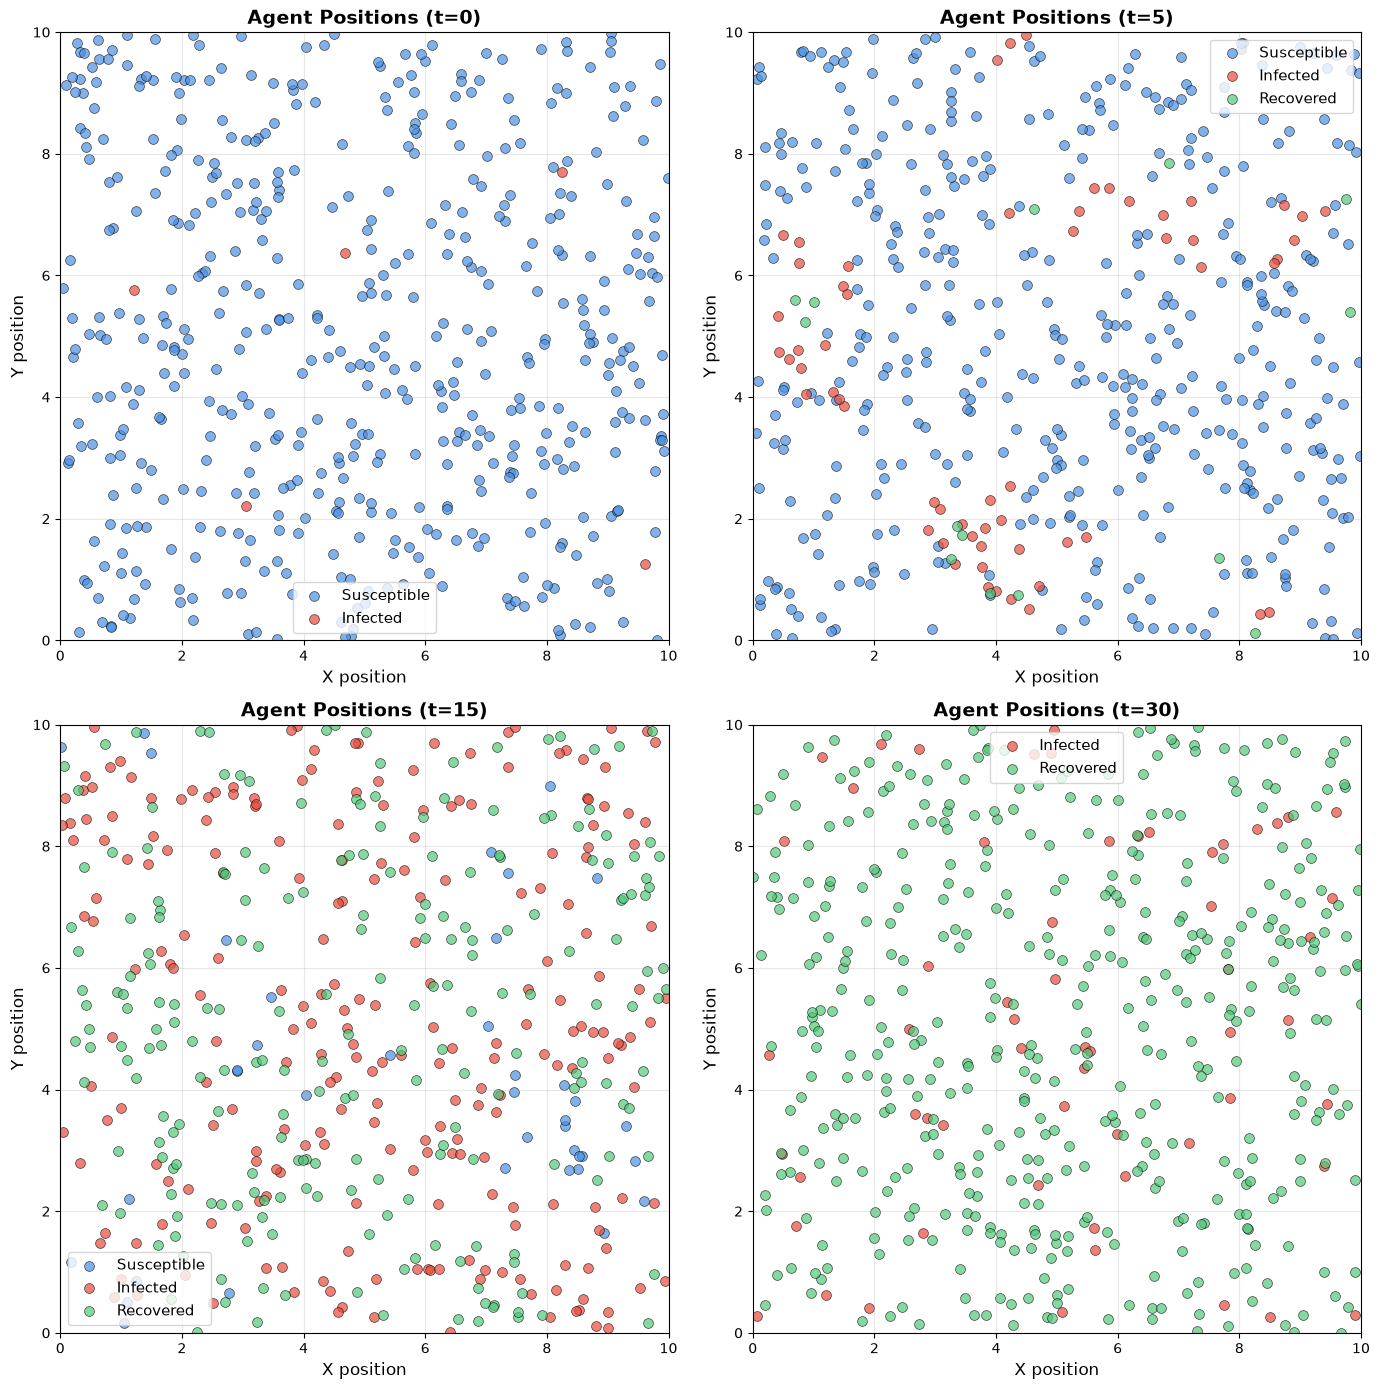


Final state: S=0, I=0, R=500


In [13]:
# Create ABM simulation
sim = ABMSimulator(
    N=500,
    beta=0.3,
    gamma=0.1,
    speed=0.5,
    contact_radius=0.5,
    domain_size=10.0,
    initial_infected=5
)

# Run simulation
print("Running ABM simulation... (may take 10-20 seconds)")
history = sim.simulate(max_steps=150)
print("✓ Simulation complete")

# Plot positions at different times
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
axes = axes.flatten()

timesteps = [0, 5, 15, 30]
for ax, t in zip(axes, timesteps):
    if t < len(sim.position_history):
        sim.plot_positions(timestep=t, ax=ax, show_contacts=False)

plt.tight_layout()
plt.show()

print(f"\nFinal state: S={history['S'][-1]}, I={history['I'][-1]}, R={history['R'][-1]}")

## Figure 22: Single ABM Trajectory

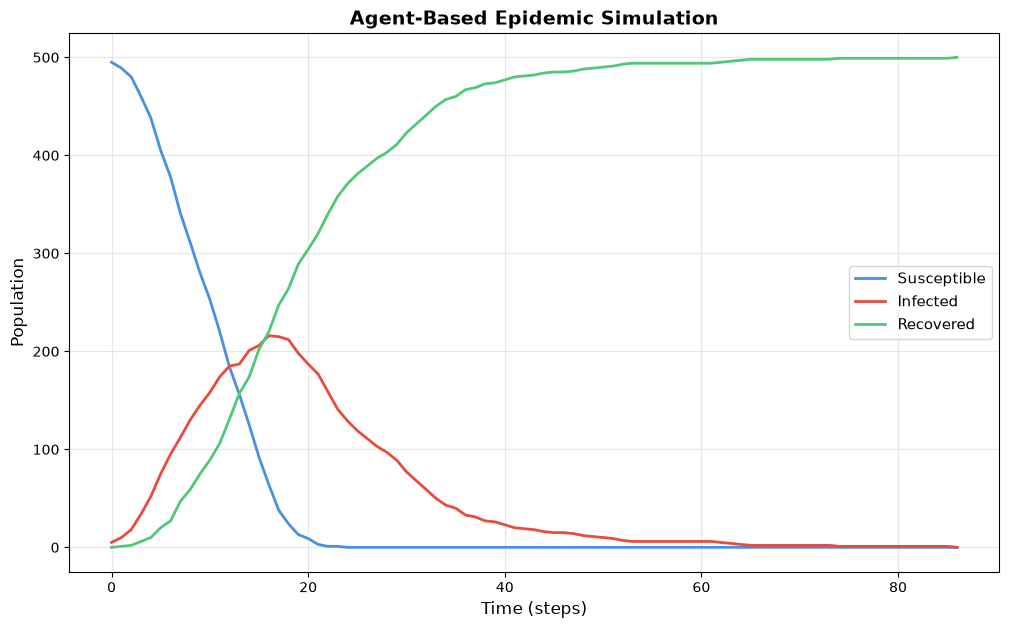

Peak infection: 216 agents at time step 16
Total infected: 500 agents (100.0%)


In [3]:
# Plot epidemic curve from ABM
fig, ax = plt.subplots(figsize=(12, 7))
plot_abm_timeseries(history, title="Agent-Based Epidemic Simulation", ax=ax)
plt.show()

# Find peak
I_vals = np.array(history['I'])
peak_idx = np.argmax(I_vals)
peak_time = peak_idx
peak_value = I_vals[peak_idx]

print(f"Peak infection: {peak_value} agents at time step {peak_time}")
print(f"Total infected: {history['R'][-1]} agents ({100*history['R'][-1]/500:.1f}%)")

## Visualizing Contact Radius

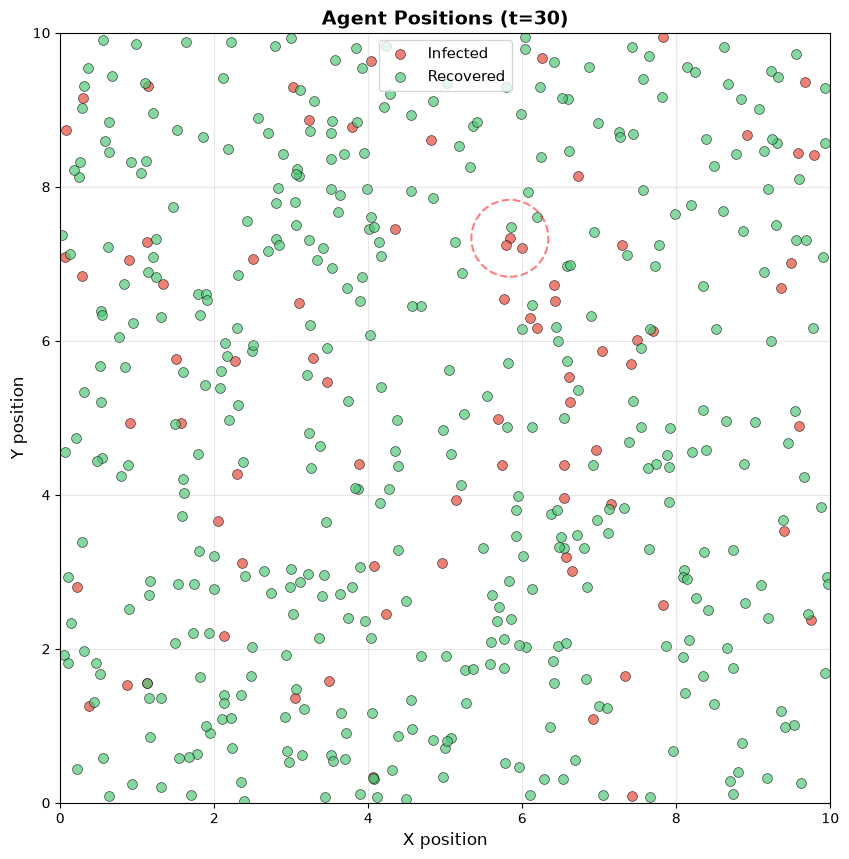

Contact radius: 0.5 units
Circles show transmission range for one infected agent


In [4]:
# Show contact radius for infected agents
fig, ax = plt.subplots(figsize=(10, 10))
sim.plot_positions(timestep=30, ax=ax, show_contacts=True)
plt.show()

print(f"Contact radius: {sim.contact_radius} units")
print("Circles show transmission range for one infected agent")

## 5.2 Stochasticity in ABM

Unlike ODE models, ABM is **stochastic** — each run is different.

We need to run **multiple simulations** and average.

## Figure 23: Multiple ABM Runs

Running 20 ABM simulations... (may take 1-2 minutes)
✓ All simulations complete


/Users/home/Desktop/知春/2025-BIO Material/Finial_Project/notebooks/../src/abm.py:427: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=11)


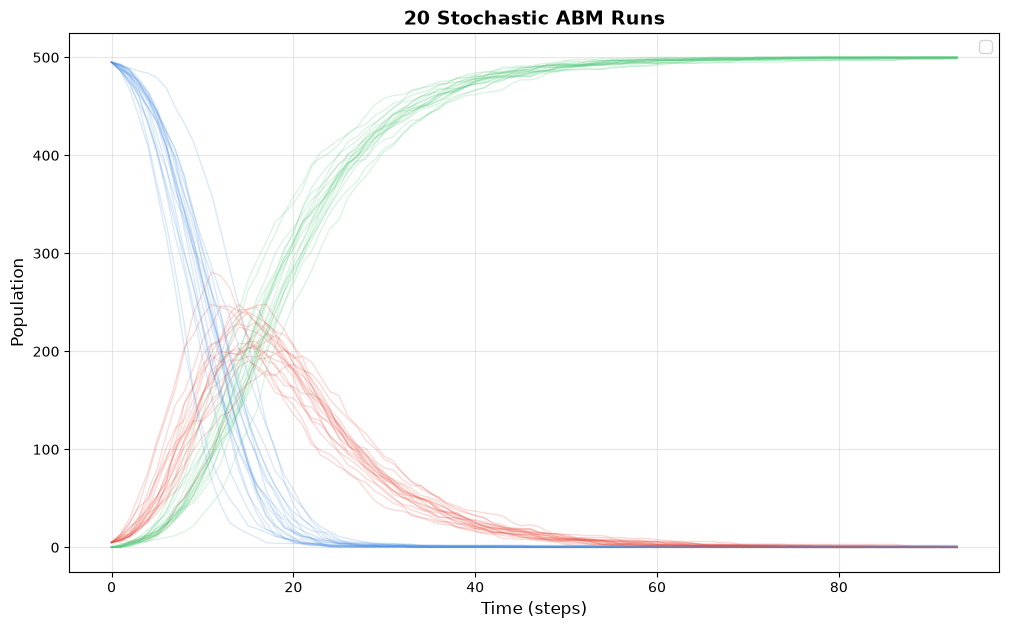


Notice the variation between runs — this is stochasticity!
Some runs have larger outbreaks, some smaller.


In [5]:
# Run multiple simulations
print("Running 20 ABM simulations... (may take 1-2 minutes)")
all_histories = run_multiple_abm_simulations(
    n_runs=20,
    N=500,
    beta=0.3,
    gamma=0.1,
    speed=0.5,
    contact_radius=0.5,
    domain_size=10.0,
    initial_infected=5,
    max_steps=150
)
print("✓ All simulations complete")

# Plot all runs
fig, ax = plt.subplots(figsize=(12, 7))
plot_multiple_runs(all_histories, 
                  title="20 Stochastic ABM Runs",
                  show_individual=True,
                  show_mean=False,
                  ax=ax)
plt.show()

print("\nNotice the variation between runs — this is stochasticity!")
print("Some runs have larger outbreaks, some smaller.")

## Figure 24: Mean Trajectory

Average over many runs to get smooth dynamics.

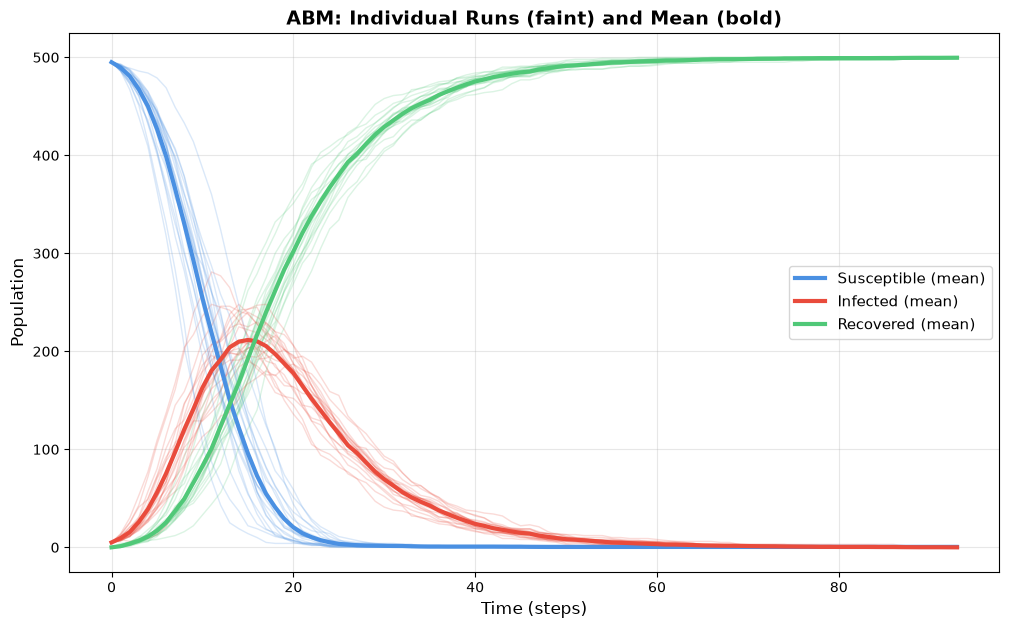


Final outbreak size:
  Mean: 499.6 ± 0.6 agents
  Range: 498 to 500 agents
  Percentage: 99.9% ± 0.1%


In [6]:
# Plot with mean trajectory highlighted
fig, ax = plt.subplots(figsize=(12, 7))
plot_multiple_runs(all_histories,
                  title="ABM: Individual Runs (faint) and Mean (bold)",
                  show_individual=True,
                  show_mean=True,
                  ax=ax)
plt.show()

# Compute statistics
final_Rs = [h['R'][-1] for h in all_histories]
mean_R = np.mean(final_Rs)
std_R = np.std(final_Rs)

print(f"\nFinal outbreak size:")
print(f"  Mean: {mean_R:.1f} ± {std_R:.1f} agents")
print(f"  Range: {min(final_Rs)} to {max(final_Rs)} agents")
print(f"  Percentage: {100*mean_R/500:.1f}% ± {100*std_R/500:.1f}%")

## Figure 25: ABM vs SIR Comparison

How does ABM compare to mean-field SIR?

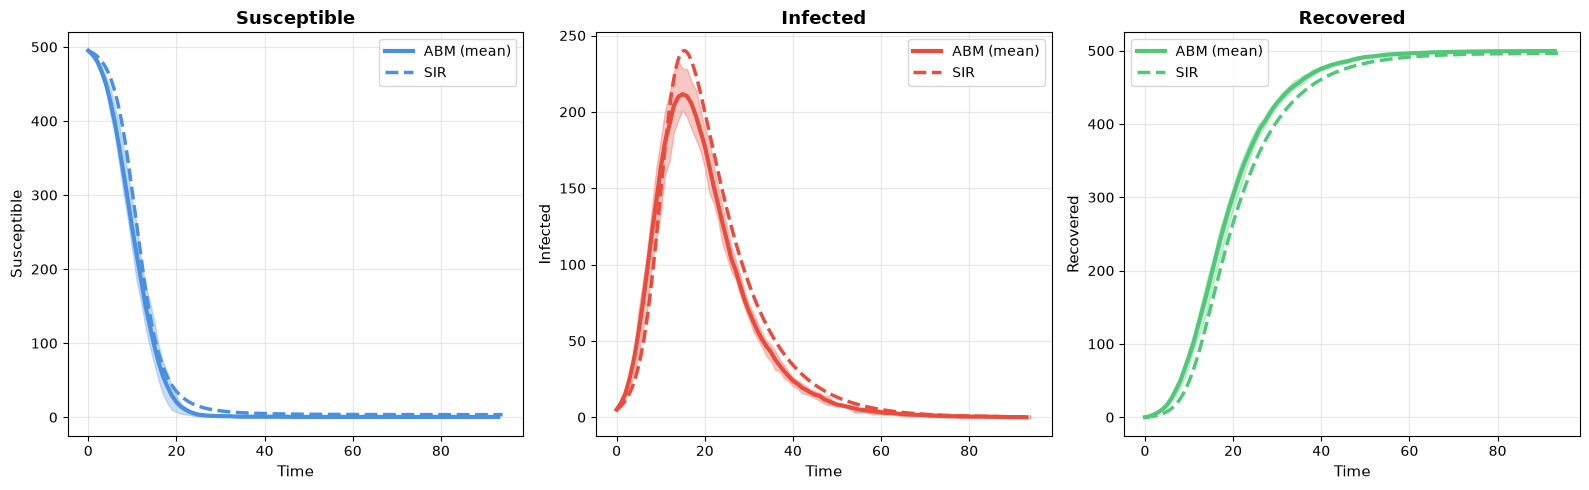


Key differences:
  • ABM shows stochasticity (shaded regions = 25-75 percentile)
  • SIR is smooth and deterministic
  • ABM spatial structure can slow spread slightly
  • Averaged ABM approaches mean-field behavior


In [7]:
# Compute mean ABM trajectory
max_len = max(len(h['S']) for h in all_histories)

def pad_history(arr, target_len):
    if len(arr) < target_len:
        return np.pad(arr, (0, target_len - len(arr)), mode='edge')
    return np.array(arr)

S_all = np.array([pad_history(h['S'], max_len) for h in all_histories])
I_all = np.array([pad_history(h['I'], max_len) for h in all_histories])
R_all = np.array([pad_history(h['R'], max_len) for h in all_histories])

S_mean = np.mean(S_all, axis=0)
I_mean = np.mean(I_all, axis=0)
R_mean = np.mean(R_all, axis=0)
t_abm = np.arange(max_len)

# Run SIR with similar parameters
# Estimate effective beta for mean-field
# In ABM: contacts happen in space, in SIR: through mass action
# Rough scaling: beta_SIR ≈ beta_ABM * (contact rate)
beta_sir = 0.5  # Adjusted to roughly match ABM dynamics
gamma_sir = 0.1

sir_sol = simulate_sir(beta=beta_sir, gamma=gamma_sir, S0=495, I0=5, R0=0, t_span=(0, max_len))

# Plot comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Susceptible
axes[0].plot(t_abm, S_mean, label='ABM (mean)', linewidth=3, color='#4A90E2')
axes[0].fill_between(t_abm, 
                     np.percentile(S_all, 25, axis=0),
                     np.percentile(S_all, 75, axis=0),
                     alpha=0.3, color='#4A90E2')
axes[0].plot(sir_sol.t, sir_sol.y[0], label='SIR', linewidth=2.5, 
            color='#4A90E2', linestyle='--')
axes[0].set_xlabel('Time', fontsize=11)
axes[0].set_ylabel('Susceptible', fontsize=11)
axes[0].set_title('Susceptible', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Infected
axes[1].plot(t_abm, I_mean, label='ABM (mean)', linewidth=3, color='#E94B3C')
axes[1].fill_between(t_abm,
                     np.percentile(I_all, 25, axis=0),
                     np.percentile(I_all, 75, axis=0),
                     alpha=0.3, color='#E94B3C')
axes[1].plot(sir_sol.t, sir_sol.y[1], label='SIR', linewidth=2.5,
            color='#E94B3C', linestyle='--')
axes[1].set_xlabel('Time', fontsize=11)
axes[1].set_ylabel('Infected', fontsize=11)
axes[1].set_title('Infected', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

# Recovered
axes[2].plot(t_abm, R_mean, label='ABM (mean)', linewidth=3, color='#50C878')
axes[2].fill_between(t_abm,
                     np.percentile(R_all, 25, axis=0),
                     np.percentile(R_all, 75, axis=0),
                     alpha=0.3, color='#50C878')
axes[2].plot(sir_sol.t, sir_sol.y[2], label='SIR', linewidth=2.5,
            color='#50C878', linestyle='--')
axes[2].set_xlabel('Time', fontsize=11)
axes[2].set_ylabel('Recovered', fontsize=11)
axes[2].set_title('Recovered', fontsize=13, fontweight='bold')
axes[2].legend(fontsize=10)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nKey differences:")
print("  • ABM shows stochasticity (shaded regions = 25-75 percentile)")
print("  • SIR is smooth and deterministic")
print("  • ABM spatial structure can slow spread slightly")
print("  • Averaged ABM approaches mean-field behavior")

## Effect of Movement Speed

Testing different movement speeds...
  Speed 0.1: final R = 407
  Speed 0.3: final R = 497
  Speed 0.5: final R = 499
  Speed 0.8: final R = 500


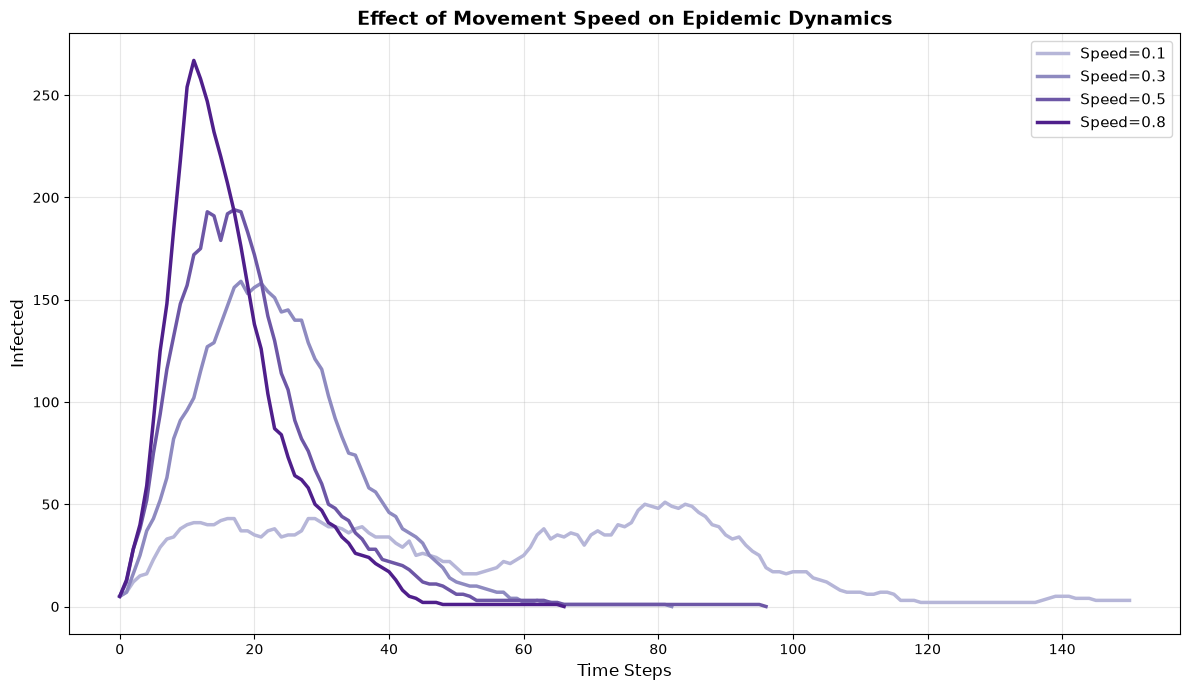


Higher movement speed → more contacts → faster spread


In [8]:
# Compare different movement speeds
speeds = [0.1, 0.3, 0.5, 0.8]
speed_results = {}

print("Testing different movement speeds...")
for speed in speeds:
    sim = ABMSimulator(N=500, beta=0.3, gamma=0.1, speed=speed,
                      contact_radius=0.5, initial_infected=5)
    history = sim.simulate(max_steps=150)
    speed_results[speed] = history
    print(f"  Speed {speed:.1f}: final R = {history['R'][-1]}")

# Plot
fig, ax = plt.subplots(figsize=(12, 7))

colors_speed = plt.cm.Purples(np.linspace(0.4, 0.9, len(speeds)))
for speed, color in zip(speeds, colors_speed):
    history = speed_results[speed]
    t = np.arange(len(history['I']))
    ax.plot(t, history['I'], label=f'Speed={speed:.1f}', 
           linewidth=2.5, color=color)

ax.set_xlabel('Time Steps', fontsize=12)
ax.set_ylabel('Infected', fontsize=12)
ax.set_title('Effect of Movement Speed on Epidemic Dynamics', 
            fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nHigher movement speed → more contacts → faster spread")

## Effect of Contact Radius

Testing different contact radii...
  Radius 0.3: final R = 474
  Radius 0.5: final R = 499
  Radius 0.7: final R = 500
  Radius 1.0: final R = 500


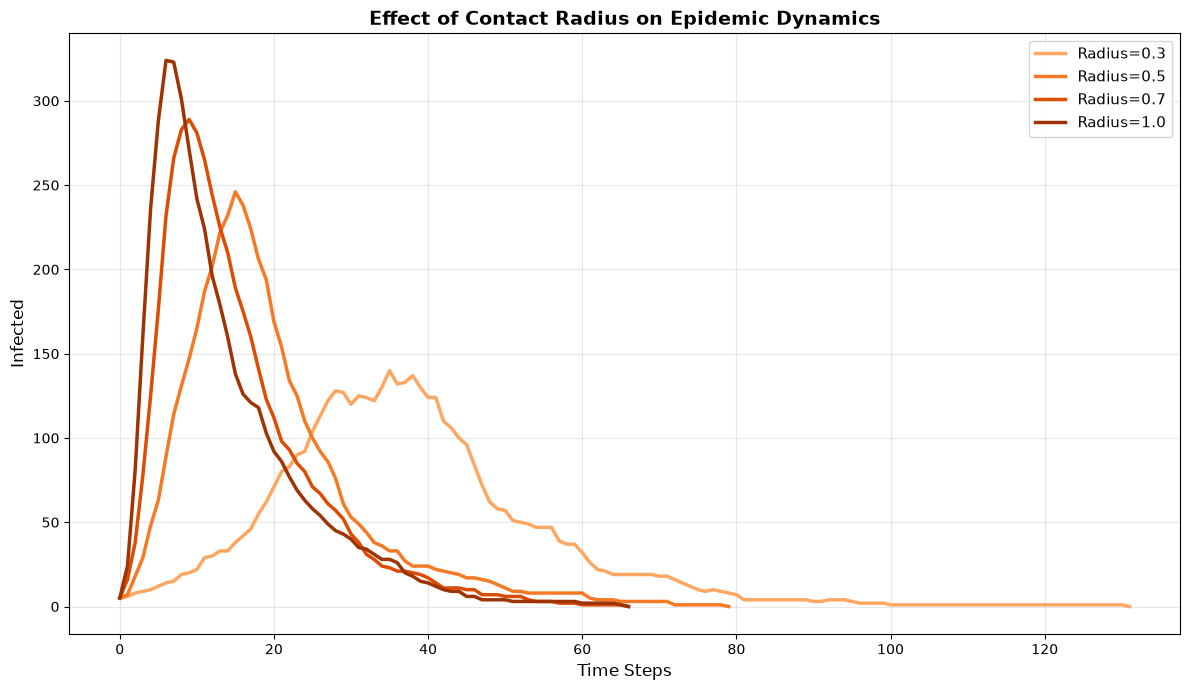


Larger contact radius → more contacts → faster spread


In [9]:
# Compare different contact radii
radii = [0.3, 0.5, 0.7, 1.0]
radius_results = {}

print("Testing different contact radii...")
for radius in radii:
    sim = ABMSimulator(N=500, beta=0.3, gamma=0.1, speed=0.5,
                      contact_radius=radius, initial_infected=5)
    history = sim.simulate(max_steps=150)
    radius_results[radius] = history
    print(f"  Radius {radius:.1f}: final R = {history['R'][-1]}")

# Plot
fig, ax = plt.subplots(figsize=(12, 7))

colors_radius = plt.cm.Oranges(np.linspace(0.4, 0.9, len(radii)))
for radius, color in zip(radii, colors_radius):
    history = radius_results[radius]
    t = np.arange(len(history['I']))
    ax.plot(t, history['I'], label=f'Radius={radius:.1f}',
           linewidth=2.5, color=color)

ax.set_xlabel('Time Steps', fontsize=12)
ax.set_ylabel('Infected', fontsize=12)
ax.set_title('Effect of Contact Radius on Epidemic Dynamics',
            fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nLarger contact radius → more contacts → faster spread")

## Summary

### What We Learned

1. **ABM is the most flexible approach**
   - Models individual agents
   - Captures spatial dynamics
   - Allows arbitrarily complex rules

2. **ABM is stochastic**
   - Each run is different
   - Need multiple runs for statistics
   - Shows natural variation

3. **Spatial structure matters**
   - Movement speed affects spread
   - Contact radius determines transmission range
   - Local clustering slows epidemics

4. **Averaged ABM approaches mean-field**
   - With many runs, ABM → ODE behavior
   - But individual runs show variation

### Advantages of ABM
- ✅ Most realistic
- ✅ Captures individual behaviors
- ✅ Spatial dynamics
- ✅ Flexible policy modeling
- ✅ Stochasticity included

### Disadvantages of ABM
- ❌ Computationally expensive
- ❌ Requires many parameters
- ❌ Harder to analyze mathematically
- ❌ Need many runs for statistics
- ❌ Can be difficult to calibrate

### When to Use ABM
- **Spatial effects** are important
- **Individual behaviors** vary significantly
- **Policy interventions** target specific locations or groups
- Need to model **complex interactions**
- Have **computational resources**

---

## The Full Hierarchy

We've now covered the complete hierarchy of epidemic models:

```
SIR (simplest)
  ↓
SEIR (add latency)
  ↓
Network SIR (add structure)
  ↓
Degree-Based (add heterogeneity analytically)
  ↓
ABM (most flexible)
```

**Next**: We'll see how real pandemic models (like COVID-19) combine multiple layers.